# CSET485 AI and Society: Assignment 1

**Roll no:** S24CSEU2649. The last digit is 9, so the dataset is **Adult Census Income**. The last three digits give the seed, `random_state = 649`, for the 70/30 train-test split.

Run the notebook top to bottom (Runtime → Restart session and run all). Every number in the PDF report is produced by these cells.

**Sections:** Preprocessing → Part 1 (build and compare) → Part 2.1 (subgroups) → 2.2 (omitted variable) → 2.3 (adversarial subset) → 2.4 (fairness trade-off).

## Preprocessing: loading the data
We load `adult.data` and `adult.test` from UCI and join them into one table of 48,842 rows (the assignment splits it ourselves later). The test file writes labels as `>50K.` with a trailing dot, so we strip it, and we turn the `?` placeholders into proper missing values (`NaN`).

In [1]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split

cols = ["age","workclass","fnlwgt","education","education_num","marital_status",
        "occupation","relationship","race","sex","capital_gain","capital_loss",
        "hours_per_week","native_country","income"]

base = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/"
train = pd.read_csv(base+"adult.data", names=cols, skipinitialspace=True)
test  = pd.read_csv(base+"adult.test", names=cols, skipinitialspace=True, skiprows=1)
df = pd.concat([train, test], ignore_index=True)

df["income"] = df["income"].str.replace(".", "", regex=False)
df = df.replace("?", np.nan)
print(df.shape)
print(df.isna().sum()[df.isna().sum() > 0])
print(df["income"].value_counts())

(48842, 15)
workclass         2799
occupation        2809
native_country     857
dtype: int64
income
<=50K    37155
>50K     11687
Name: count, dtype: int64


### Preprocessing: is the missing data random?
Before deciding between dropping and filling, we check three things: how many rows are affected, whether `workclass` and `occupation` go missing together, and whether the people with missing values earn differently from everyone else. Result: 3,620 rows (7.41%) are affected, the two columns go missing together, and only 13.2% of those rows earn >50K against 24.8% for complete rows. So the missingness is not random.

In [2]:
# 1. How many rows have at least one missing value?
any_missing = df[["workclass","occupation","native_country"]].isna().any(axis=1)
print("Rows with any missing:", any_missing.sum(), f"({any_missing.mean()*100:.2f}%)")

# 2. Do workclass and occupation go missing together?
both = (df["workclass"].isna() & df["occupation"].isna()).sum()
print("Both workclass and occupation missing:", both)

# 3. Does missingness relate to income?
print("Income >50K rate, rows with missing:", (df.loc[any_missing,"income"]==">50K").mean().round(3))
print("Income >50K rate, rows complete:   ", (df.loc[~any_missing,"income"]==">50K").mean().round(3))

Rows with any missing: 3620 (7.41%)
Both workclass and occupation missing: 2799
Income >50K rate, rows with missing: 0.132
Income >50K rate, rows complete:    0.248


### Preprocessing: fill missing values with "Unknown"
We fill the gaps with an explicit `"Unknown"` category instead of dropping rows. Dropping the 3,620 rows would remove a group that is systematically lower-income (13.2% vs 24.8%), making the remaining population look richer than it is and biasing the model against exactly those people. As a category, "Unknown" lets the model learn from the missingness itself. We apply the same treatment to `native_country` for consistency.

In [3]:
for c in ["workclass", "occupation", "native_country"]:
    df[c] = df[c].fillna("Unknown")

print(df.isna().sum().sum())   # should print 0
print(df.shape)                # should still be (48842, 15)

0
(48842, 15)


### Preprocessing: drop columns, encode the target, look for outliers
- `education` is dropped because `education_num` carries the same information as an ordered number (this avoids 16 extra dummy columns).
- `fnlwgt` is dropped because it is a census sampling weight that describes how the survey was built, not the person.
- The target is encoded as 1 if income is >50K, else 0.
- `describe()` on the numeric columns shows whether any values look impossible or extreme.

In [4]:
df = df.drop(columns=["education", "fnlwgt"])
df["target"] = (df["income"] == ">50K").astype(int)
df = df.drop(columns=["income"])

num_cols = ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
print(df[num_cols].describe().round(1))

print("\ncapital_gain == 0:", (df["capital_gain"] == 0).mean().round(3))
print("capital_gain == 99999:", (df["capital_gain"] == 99999).sum())
print("capital_loss == 0:", (df["capital_loss"] == 0).mean().round(3))

           age  education_num  capital_gain  capital_loss  hours_per_week
count  48842.0        48842.0       48842.0       48842.0         48842.0
mean      38.6           10.1        1079.1          87.5            40.4
std       13.7            2.6        7452.0         403.0            12.4
min       17.0            1.0           0.0           0.0             1.0
25%       28.0            9.0           0.0           0.0            40.0
50%       37.0           10.0           0.0           0.0            40.0
75%       48.0           12.0           0.0           0.0            45.0
max       90.0           16.0       99999.0        4356.0            99.0

capital_gain == 0: 0.917
capital_gain == 99999: 244
capital_loss == 0: 0.953


### Preprocessing: outliers in `capital_gain` and `capital_loss`
Both are mostly zeros (91.7% and 95.3%), with a few huge values. The 244 rows at exactly 99,999 are a top-coded cap, not errors: all of them earn >50K, so we **keep** them. To stop a handful of extreme values from dominating the coefficients, we apply `log(1 + x)` to both columns. `hours_per_week` of 80 or more (528 rows) is plausible for survey answers, and `age` (17 to 90) and `education_num` (1 to 16) are in valid ranges, so we leave those unchanged.

In [5]:
top = df[df["capital_gain"] == 99999]
print("Rows at 99999:", len(top))
print("Share earning >50K among them:", top["target"].mean().round(3))
print("Share earning >50K among capital_gain > 0 (excl. 99999):",
      df[(df["capital_gain"] > 0) & (df["capital_gain"] < 99999)]["target"].mean().round(3))
print("Rows with hours_per_week >= 80:", (df["hours_per_week"] >= 80).sum())

df["capital_gain"] = np.log1p(df["capital_gain"])
df["capital_loss"] = np.log1p(df["capital_loss"])
print(df[["capital_gain","capital_loss"]].describe().round(2))

Rows at 99999: 244
Share earning >50K among them: 1.0
Share earning >50K among capital_gain > 0 (excl. 99999): 0.593
Rows with hours_per_week >= 80: 528
       capital_gain  capital_loss
count      48842.00      48842.00
mean           0.73          0.35
std            2.45          1.59
min            0.00          0.00
25%            0.00          0.00
50%            0.00          0.00
75%            0.00          0.00
max           11.51          8.38


### Preprocessing: encoding, redundant columns, split and scaling
- **Encoding:** one-hot encoding with `drop_first=True`, so each categorical variable has a reference category and no column is a perfect copy of the others (for example the reference for `marital_status` is Divorced and for `relationship` is Husband).
- **Two more columns removed:** `occupation_Unknown` is exactly `workclass_Unknown + workclass_Never-worked` (2,799 + 10 = 2,809 rows), which made the design matrix singular and the standard errors `NaN`. `native_country_Holand-Netherlands` appears in only 1 row, so it is all zeros in the training set. After removal there are 82 predictors and the matrix rank is 82.
- **Split first, then scale:** 70/30 split with `random_state=649`. `StandardScaler` is fitted on the training rows only and then applied to both sets, so no information from the test set leaks into training. Only the five numeric columns are scaled.

In [6]:
import statsmodels.api as sm
from scipy import stats
from sklearn.preprocessing import StandardScaler

cat_cols = ["workclass", "marital_status", "occupation", "relationship",
            "race", "sex", "native_country"]
num_cols = ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"]

X = pd.get_dummies(df.drop(columns="target"), columns=cat_cols, drop_first=True, dtype=int)
y = df["target"]

# remove redundant columns BEFORE splitting
X = X.drop(columns=["occupation_Unknown",                   # = workclass_Unknown + workclass_Never-worked
                    "native_country_Holand-Netherlands"])   # only 1 row in the whole dataset

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=649)
X_train, X_test = X_train.copy(), X_test.copy()

scaler = StandardScaler().fit(X_train[num_cols])
X_train[num_cols] = scaler.transform(X_train[num_cols])
X_test[num_cols]  = scaler.transform(X_test[num_cols])

sex_train = X_train["sex_Male"]      # 1 = male, 0 = female

print("X shape:", X.shape)           # expect (48842, 82)
print("columns:", X_train.shape[1], " rank:", np.linalg.matrix_rank(X_train.astype(float).values))

X shape: (48842, 82)
columns: 82  rank: 82


## Part 1: Build and compare the two models
- **Model A** is OLS on the 0/1 target. Its output is a continuous score, and a person is "high risk" if the score is at or above the **median** of the test predictions.
- **Model B** is logistic regression. A person is "high risk" if the predicted probability is **at least 0.5**.

We compare the two flags with a confusion matrix and count the mismatches. The median rule flags exactly 50% of people by construction, while the 0.5 rule flags only people judged more likely than not to earn >50K.

In [7]:
from sklearn.linear_model import LinearRegression, LogisticRegression

# Model A: OLS predicting the 0/1 target as a number
lin = LinearRegression().fit(X_train, y_train)
pred_A = lin.predict(X_test)
median_A = np.median(pred_A)
flag_A = (pred_A >= median_A).astype(int)      # high risk if >= median

# Model B: logistic regression, threshold 0.5
logit = LogisticRegression(penalty=None, max_iter=5000).fit(X_train, y_train)
prob_B = logit.predict_proba(X_test)[:, 1]
flag_B = (prob_B >= 0.5).astype(int)

print("Model A median prediction:", round(median_A, 4))
print("Model A range:", pred_A.min().round(3), "to", pred_A.max().round(3))
print("Flagged high-risk  A:", flag_A.sum(), f"({flag_A.mean()*100:.1f}%)",
      "  B:", flag_B.sum(), f"({flag_B.mean()*100:.1f}%)")

print(pd.crosstab(flag_A, flag_B, rownames=["A (linear >= median)"],
                  colnames=["B (logistic >= 0.5)"]))

mismatch = (flag_A != flag_B).sum()
print("Mismatched:", mismatch, f"({mismatch/len(flag_A)*100:.2f}%)")

Model A median prediction: 0.2231
Model A range: -0.405 to 1.252
Flagged high-risk  A: 7327 (50.0%)   B: 2829 (19.3%)
B (logistic >= 0.5)      0     1
A (linear >= median)            
0                     7326     0
1                     4498  2829
Mismatched: 4498 (30.70%)


### Part 1: why do they disagree?
Three checks to separate cutoff effects from model effects: (1) how many OLS predictions fall outside 0 to 1 and so cannot be probabilities; (2) the mismatch when logistic regression also uses its own median, which isolates the ranking difference from the cutoff difference; (3) accuracy against the true labels, which shows the cost of forcing 50% to be flagged.

In [8]:
# 1. How many linear predictions are impossible as probabilities?
print("A predictions < 0:", (pred_A < 0).sum(), "  > 1:", (pred_A > 1).sum())

# 2. Put B on the same footing: flag its top 50% using its own median
median_B = np.median(prob_B)
flag_B_med = (prob_B >= median_B).astype(int)
mm2 = (flag_A != flag_B_med).sum()
print("B median prob:", round(median_B, 4))
print("Mismatch when both use their own median:", mm2, f"({mm2/len(flag_A)*100:.2f}%)")

# 3. Accuracy of each flag against the real outcome
print("Accuracy A (median):", (flag_A == y_test).mean().round(3))
print("Accuracy B (0.5):   ", (flag_B == y_test).mean().round(3))

A predictions < 0: 3125   > 1: 59
B median prob: 0.105
Mismatch when both use their own median: 748 (5.10%)
Accuracy A (median): 0.711
Accuracy B (0.5):    0.841


## Part 2.1: Subgroup analysis by sex
We split the data by `sex` and fit logistic regression on the full training set, on women only and on men only, tracking `education_num` (standardised, so one unit is about 2.6 years of education). We use `statsmodels` because it gives confidence intervals and p-values. `fit_logit` drops columns that are constant inside the data being fitted (for example `occupation_Armed-Forces` has no women) and uses BFGS with many iterations so the fits converge.

In [9]:
def fit_logit(Xs, ys, drop=[]):
    Xs = Xs.drop(columns=drop).astype(float)
    constant = Xs.columns[Xs.nunique() <= 1].tolist()
    Xs = sm.add_constant(Xs.drop(columns=constant))
    m = sm.Logit(ys, Xs).fit(method="bfgs", maxiter=5000, disp=0)
    print(f"  dropped {constant} | converged: {m.mle_retvals['converged']}")
    return m

print("Full:");   m_full = fit_logit(X_train, y_train)
print("Female:"); m_fem  = fit_logit(X_train[sex_train == 0], y_train[sex_train == 0], drop=["sex_Male"])
print("Male:");   m_male = fit_logit(X_train[sex_train == 1], y_train[sex_train == 1], drop=["sex_Male"])

for name, m in [("Full", m_full), ("Female", m_fem), ("Male", m_male)]:
    ci = m.conf_int().loc["education_num"]
    print(f"{name:7s} coef={m.params['education_num']:.3f}  "
          f"95% CI=({ci[0]:.3f}, {ci[1]:.3f})  p={m.pvalues['education_num']:.4f}  n={int(m.nobs)}")

Full:
  dropped [] | converged: True
Female:
  dropped ['occupation_Armed-Forces'] | converged: True
Male:
  dropped [] | converged: True
Full    coef=0.730  95% CI=(0.686, 0.775)  p=0.0000  n=34189
Female  coef=0.960  95% CI=(0.842, 1.077)  p=0.0000  n=11366
Male    coef=0.689  95% CI=(0.641, 0.738)  p=0.0000  n=22823


### Part 2.1: is the difference real?
Comparing confidence intervals by eye is not a formal test. We add an interaction term, `education_num × sex_Male`, to the full model. Its coefficient is the difference between men's and women's education effect, and it comes with its own confidence interval and p-value.

In [10]:
# Formal test: does education's effect differ by sex?
Xi = X_train.astype(float).copy()
Xi["edu_x_male"] = Xi["education_num"] * Xi["sex_Male"]
const = Xi.columns[Xi.nunique() <= 1].tolist()
Xi = sm.add_constant(Xi.drop(columns=const))
m_int = sm.Logit(y_train, Xi).fit(method="bfgs", maxiter=5000, disp=0)
print("converged:", m_int.mle_retvals["converged"])

ci = m_int.conf_int().loc["edu_x_male"]
print(f"interaction coef={m_int.params['edu_x_male']:.3f}  "
      f"95% CI=({ci[0]:.3f}, {ci[1]:.3f})  p={m_int.pvalues['edu_x_male']:.2e}")
print("education_num main effect (women):", m_int.params["education_num"].round(3))

# Context for your explanation: base rates by sex
print("\nShare earning >50K by sex (train):")
print(y_train.groupby(sex_train.map({0: "Female", 1: "Male"})).mean().round(3))

converged: True
interaction coef=-0.231  95% CI=(-0.338, -0.124)  p=2.20e-05
education_num main effect (women): 0.925

Share earning >50K by sex (train):
sex_Male
Female    0.110
Male      0.304
Name: target, dtype: float64


## Part 2.2: Omitted-variable bias
We drop all 13 `occupation_*` columns because occupation is tied to education, hours worked, age and sex, so leaving it out should distort the coefficients of the variables correlated with it. We refit the reduced model and compare it with the full model for five predictors. Percentage change is `(reduced − full) / |full| × 100`, using the absolute value of the full coefficient so the direction of the shift is clear.

In [11]:
occ_cols = [c for c in X_train.columns if c.startswith("occupation_")]
print("occupation columns dropped:", len(occ_cols))

m_red = fit_logit(X_train, y_train, drop=occ_cols)      # reduced model; m_full is the full model

keys = ["age", "education_num", "hours_per_week", "sex_Male", "capital_gain"]
cmp = pd.DataFrame({"full": m_full.params[keys], "reduced": m_red.params[keys]})
cmp["pct_change"] = (cmp["reduced"] - cmp["full"]) / cmp["full"].abs() * 100
print(cmp.round(3))

occupation columns dropped: 13
  dropped [] | converged: True
                 full  reduced  pct_change
age             0.385    0.398       3.459
education_num   0.730    0.933      27.775
hours_per_week  0.399    0.406       1.655
sex_Male        0.672    0.636      -5.315
capital_gain    0.518    0.519       0.212


## Part 2.3: Adversarial subset
On the test set we find where Model B is confidently wrong: probability ≥ 0.75 but the person actually earns ≤50K (false positive), or probability ≤ 0.25 but the person actually earns >50K (false negative). We count them, sample 50 rows with `random_state=649`, and compare the 50 with the full test set. We use the unscaled columns for readability, so note that `capital_gain` is still on the log scale.

In [12]:
test_df = df.loc[y_test.index].copy()          # original (unscaled) columns, same rows as the test set
test_df["prob"] = prob_B
test_df["y"] = y_test.values

fp = (test_df["prob"] >= 0.75) & (test_df["y"] == 0)      # confident false positive
fn = (test_df["prob"] <= 0.25) & (test_df["y"] == 1)      # confident false negative
wrong = test_df[fp | fn]
print("Confident wrong:", len(wrong), f"({len(wrong)/len(test_df)*100:.2f}% of test)")
print("  false positives:", fp.sum(), "  false negatives:", fn.sum())

adv = wrong.sample(n=min(50, len(wrong)), random_state=649)   # the 50-row subset
print("Subset size:", len(adv))

nums = ["age", "education_num", "hours_per_week", "capital_gain"]
print(pd.DataFrame({"adv_50": adv[nums].mean(), "full_test": test_df[nums].mean()}).round(2))

for c in ["sex", "marital_status", "relationship", "race"]:
    t = pd.concat([adv[c].value_counts(normalize=True).rename("adv_50"),
                   test_df[c].value_counts(normalize=True).rename("full_test")], axis=1)
    print("\n", (t * 100).round(1).sort_values("adv_50", ascending=False).head(4))

Confident wrong: 821 (5.60% of test)
  false positives: 195   false negatives: 626
Subset size: 50
                adv_50  full_test
age              43.72      38.63
education_num    11.42      10.08
hours_per_week   45.84      40.53
capital_gain      1.03       0.71

         adv_50  full_test
sex                      
Male      76.0       67.1
Female    24.0       32.9

                     adv_50  full_test
marital_status                       
Married-civ-spouse    62.0       45.5
Never-married         20.0       33.6
Divorced              10.0       13.4
Widowed                4.0        3.0

                adv_50  full_test
relationship                    
Husband          54.0       40.3
Not-in-family    28.0       25.8
Wife             10.0        4.5
Unmarried         6.0       10.8

                     adv_50  full_test
race                                 
White                 88.0       85.6
Black                 10.0        9.7
Other                  2.0        0.8
Asi

### Part 2.3: looking at all the confident errors
Fifty rows is a small sample (a 62% share has a margin of roughly ±13 points), so we also profile **all** confident errors, split by false positives and false negatives. We then test two ideas for why the model fails: a non-linear age effect (actual vs predicted rate by age band) and an interaction between education and marriage (actual vs predicted rate in four groups).

In [13]:
fp_rows, fn_rows = test_df[fp], test_df[fn]
test_df["married"] = (test_df["marital_status"] == "Married-civ-spouse").astype(int)

def profile(d):
    return pd.Series({"n": len(d), "age": d.age.mean(), "edu": d.education_num.mean(),
                      "hours": d.hours_per_week.mean(), "pct_married": d.married.mean()*100,
                      "pct_male": (d.sex == "Male").mean()*100,
                      "pct_capgain>0": (d.capital_gain > 0).mean()*100})

print(pd.DataFrame({"false_pos(195)": profile(test_df[fp]),
                    "false_neg(626)": profile(test_df[fn]),
                    "full_test": profile(test_df)}).round(1))

# Guess 1: is the age effect non-linear? (actual rate vs model's average prediction)
test_df["age_band"] = pd.cut(test_df.age, [16, 25, 35, 45, 55, 65, 91])
print(test_df.groupby("age_band", observed=True).agg(
    n=("y", "size"), actual=("y", "mean"), predicted=("prob", "mean")).round(3))

# Guess 2: does education work differently for married vs unmarried people?
test_df["college"] = (test_df.education_num >= 13).astype(int)
print(test_df.groupby(["married", "college"]).agg(
    n=("y", "size"), actual=("y", "mean"), predicted=("prob", "mean")).round(3))

               false_pos(195)  false_neg(626)  full_test
n                       195.0           626.0    14653.0
age                      49.9            41.6       38.6
edu                      12.8            10.0       10.1
hours                    52.0            42.0       40.5
pct_married              96.9            50.0       45.5
pct_male                 89.2            72.0       67.1
pct_capgain>0            30.3             4.2        8.1
             n  actual  predicted
age_band                         
(16, 25]  2875   0.017      0.037
(25, 35]  3863   0.193      0.200
(35, 45]  3489   0.351      0.309
(45, 55]  2543   0.382      0.355
(55, 65]  1349   0.308      0.346
(65, 91]   534   0.184      0.287
                    n  actual  predicted
married college                         
0       0        6312   0.033      0.033
        1        1677   0.197      0.178
1       0        4700   0.333      0.331
        1        1964   0.713      0.722


### Part 2.3: are the confident errors expected?
A calibrated model that says 0.87 will be wrong about 13% of the time, so some confident errors are unavoidable. We compare the share that was actually wrong with what the model's own probabilities predict in each confidence band, and print the key coefficients to explain what the model relies on. Note that `drop_first` makes the reference groups Divorced (marital status) and Husband (relationship). The cell rebuilds `test_df` so it can be re-run on its own.

In [14]:
# rebuild what this check needs (safe to re-run)
test_df = df.loc[y_test.index].copy()          # original unscaled columns, same rows as the test set
test_df["prob"] = prob_B
test_df["y"] = y_test.values

hi = test_df[test_df.prob >= 0.75]
lo = test_df[test_df.prob <= 0.25]

for k in ["marital_status_Married-civ-spouse", "education_num", "age", "hours_per_week", "capital_gain"]:
    print(f"{k:35s} coef={m_full.params[k]:.3f}")

rel = [c for c in m_full.params.index if c.startswith("relationship_")]
print("\n", m_full.params[rel].round(3))     # relative to the dropped group, Husband

print("\nP>=0.75: n =", len(hi), " actually 0:", (hi.y == 0).sum(), f"({(hi.y == 0).mean()*100:.1f}%)")
print("P<=0.25: n =", len(lo), " actually 1:", (lo.y == 1).sum(), f"({(lo.y == 1).mean()*100:.1f}%)")
print("Mean predicted P among P>=0.75:", hi.prob.mean().round(3),
      "-> expected share wrong:", round((1 - hi.prob.mean()) * 100, 1), "%")
print("Mean predicted P among P<=0.25:", lo.prob.mean().round(3),
      "-> expected share wrong:", round(lo.prob.mean() * 100, 1), "%")

marital_status_Married-civ-spouse   coef=2.193
education_num                       coef=0.730
age                                 coef=0.385
hours_per_week                      coef=0.399
capital_gain                        coef=0.518

 relationship_Not-in-family     0.477
relationship_Other-relative   -0.476
relationship_Own-child        -0.517
relationship_Unmarried         0.169
relationship_Wife              1.095
dtype: float64

P>=0.75: n = 1244  actually 0: 195 (15.7%)
P<=0.25: n = 9519  actually 1: 626 (6.6%)
Mean predicted P among P>=0.75: 0.867 -> expected share wrong: 13.3 %
Mean predicted P among P<=0.25: 0.061 -> expected share wrong: 6.1 %


## Part 2.4: Fairness trade-off analysis
We use **sex** as the sensitive variable (Group A = Female, Group B = Male), which continues the analysis from 2.1. We sweep the threshold from 0.05 to 0.95 in steps of 0.1, classify as 1 if P ≥ t, and compute Demographic Parity, Equalized Odds and Predictive Parity as defined in the assignment. `sdiv` returns `NaN` instead of dividing by zero when a group has no flagged people. The chart has the required 0 to 1.5 axes on the left and a zoomed copy on the right so the threshold labels are readable. It is saved as `tradeoff.png`.

         DP     EO     PP    acc  sel_F  sel_M  flagged_F  flagged_M
t                                                                   
0.05  0.470  0.442  0.708  0.630  0.341  0.726       1648       7139
0.15  0.309  0.254  0.945  0.754  0.178  0.576        858       5659
0.25  0.282  0.228  0.972  0.803  0.130  0.459        625       4509
0.35  0.276  0.223  0.979  0.830  0.100  0.363        484       3565
0.45  0.266  0.208  0.999  0.839  0.077  0.288        370       2828
0.55  0.251  0.186  1.019  0.839  0.057  0.227        275       2230
0.65  0.249  0.196  0.998  0.834  0.042  0.170        204       1670
0.75  0.240  0.192  0.995  0.819  0.027  0.113        131       1113
0.85  0.225  0.223  0.973  0.799  0.014  0.063         69        624
0.95  0.192  0.264  0.976  0.775  0.004  0.021         19        202


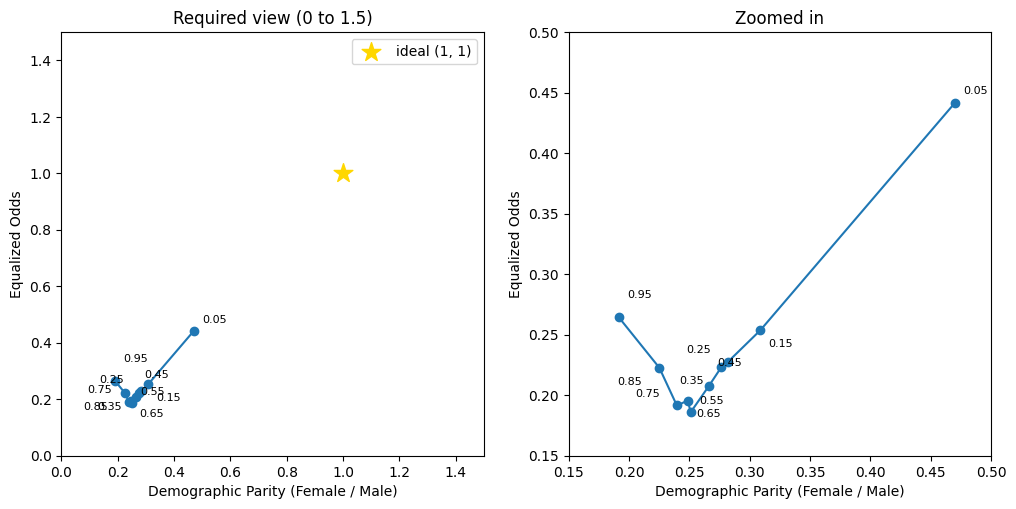

In [15]:
import matplotlib.pyplot as plt

is_male = (test_df["sex"] == "Male").values       # aligned with prob_B and y_test
y_t = y_test.values
thresholds = np.round(np.arange(0.05, 0.96, 0.1), 2)

def sdiv(a, b):
    return a / b if b > 0 else np.nan

def rates(pred, y, mask):
    p, t = pred[mask], y[mask]
    return dict(sel=p.mean(),
                tpr=sdiv(((p == 1) & (t == 1)).sum(), (t == 1).sum()),
                fpr=sdiv(((p == 1) & (t == 0)).sum(), (t == 0).sum()),
                ppv=sdiv(((p == 1) & (t == 1)).sum(), (p == 1).sum()),
                n_flag=int(p.sum()))

rows = []
for t in thresholds:
    pred = (prob_B >= t).astype(int)
    A, B = rates(pred, y_t, ~is_male), rates(pred, y_t, is_male)      # A = Female, B = Male
    r_tpr, r_fpr = sdiv(A["tpr"], B["tpr"]), sdiv(A["fpr"], B["fpr"])
    rows.append(dict(t=t,
                     DP=sdiv(A["sel"], B["sel"]),
                     EO=min(r_tpr, r_fpr) if not (np.isnan(r_tpr) or np.isnan(r_fpr)) else np.nan,
                     PP=sdiv(A["ppv"], B["ppv"]),
                     acc=(pred == y_t).mean(),
                     sel_F=A["sel"], sel_M=B["sel"], flagged_F=A["n_flag"], flagged_M=B["n_flag"]))


fair = pd.DataFrame(rows).set_index("t")
print(fair.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

for ax, lim in zip(axes, [(0, 1.5), (0.15, 0.5)]):
    ax.plot(fair.DP, fair.EO, "-o")
    for i, (t, r) in enumerate(fair.iterrows()):
        ax.annotate(f"{t:.2f}", (r.DP, r.EO), textcoords="offset points",
                    xytext=[(6, 6), (6, -12), (-30, 6), (-30, -12), (6, 14)][i % 5], fontsize=8)
    if lim[1] == 1.5:
        ax.scatter([1], [1], marker="*", s=200, color="gold", zorder=5, label="ideal (1, 1)"); ax.legend()
    ax.set_xlim(*lim); ax.set_ylim(*lim)
    ax.set_xlabel("Demographic Parity (Female / Male)"); ax.set_ylabel("Equalized Odds")
axes[0].set_title("Required view (0 to 1.5)"); axes[1].set_title("Zoomed in")
plt.savefig("tradeoff.png", dpi=200, bbox_inches="tight"); plt.show()

### Part 2.4: quantifying the trade-off
`compare` gives the percentage change in DP, EO, PP and accuracy between two thresholds, which we use for the "gain vs cost" statement. We also print the TPR, FPR and precision for each group at t = 0.05, 0.35 and 0.55 to show what each threshold means for individual people.

In [16]:
def compare(t1, t2):
    a, b = fair.loc[t1], fair.loc[t2]
    print(f"--- t={t1} -> t={t2}")
    for m in ["DP", "EO", "PP", "acc"]:
        print(f"{m}: {a[m]:.3f} -> {b[m]:.3f}  ({(b[m]-a[m])/a[m]*100:+.1f}%)")

compare(0.55, 0.05)
compare(0.85, 0.95)

print("\nBase rate in test: Female", y_t[~is_male].mean().round(3), " Male", y_t[is_male].mean().round(3))
for t in [0.05, 0.35, 0.55]:
    pred = (prob_B >= t).astype(int)
    for name, mask in [("Female", ~is_male), ("Male", is_male)]:
        r = rates(pred, y_t, mask)
        print(f"t={t:.2f} {name:6s} flagged={r['sel']*100:5.1f}%  TPR={r['tpr']:.3f}  FPR={r['fpr']:.3f}  precision={r['ppv']:.3f}")

--- t=0.55 -> t=0.05
DP: 0.251 -> 0.470  (+87.2%)
EO: 0.186 -> 0.442  (+137.6%)
PP: 1.019 -> 0.708  (-30.5%)
acc: 0.839 -> 0.630  (-25.0%)
--- t=0.85 -> t=0.95
DP: 0.225 -> 0.192  (-14.9%)
EO: 0.223 -> 0.264  (+18.7%)
PP: 0.973 -> 0.976  (+0.4%)
acc: 0.799 -> 0.775  (-3.0%)

Base rate in test: Female 0.107  Male 0.304
t=0.05 Female flagged= 34.1%  TPR=0.932  FPR=0.271  precision=0.292
t=0.05 Male   flagged= 72.6%  TPR=0.987  FPR=0.612  precision=0.413
t=0.35 Female flagged= 10.0%  TPR=0.574  FPR=0.043  precision=0.614
t=0.35 Male   flagged= 36.3%  TPR=0.748  FPR=0.195  precision=0.627
t=0.55 Female flagged=  5.7%  TPR=0.395  FPR=0.016  precision=0.742
t=0.55 Male   flagged= 22.7%  TPR=0.543  FPR=0.089  precision=0.728


### Part 2.4: TPR and FPR shown separately
Equalized Odds takes the smaller of the TPR ratio and the FPR ratio, so it hides one of them. This table shows both. In this data the FPR ratio is always the smaller one, so EO equals the FPR ratio at every threshold, and the TPR gap (qualifying women being flagged less often than qualifying men) can only be read here.

In [17]:
rows = []
for t in thresholds:
    pred = (prob_B >= t).astype(int)
    A, B = rates(pred, y_t, ~is_male), rates(pred, y_t, is_male)
    rows.append(dict(t=t, TPR_F=A["tpr"], TPR_M=B["tpr"], TPR_ratio=sdiv(A["tpr"], B["tpr"]),
                     FPR_F=A["fpr"], FPR_M=B["fpr"], FPR_ratio=sdiv(A["fpr"], B["fpr"])))
print(pd.DataFrame(rows).set_index("t").round(3))

      TPR_F  TPR_M  TPR_ratio  FPR_F  FPR_M  FPR_ratio
t                                                     
0.05  0.932  0.987      0.944  0.271  0.612      0.442
0.15  0.778  0.939      0.828  0.106  0.417      0.254
0.25  0.662  0.849      0.779  0.066  0.288      0.228
0.35  0.574  0.748      0.768  0.043  0.195      0.223
0.45  0.485  0.642      0.756  0.028  0.133      0.208
0.55  0.395  0.543      0.726  0.016  0.089      0.186
0.65  0.309  0.439      0.705  0.010  0.052      0.196
0.75  0.213  0.314      0.677  0.005  0.025      0.192
0.85  0.118  0.190      0.622  0.002  0.008      0.223
0.95  0.035  0.066      0.531  0.000  0.001      0.264
